In [106]:
#Pandasのインポートとmatplotlibからpyplotをインポートをする
import pandas as pd
from matplotlib import pyplot as plt

In [107]:
#pyplotを日本語対応させる
!pip install japanize-matplotlib

In [108]:
#日本語版をインポートする
import japanize_matplotlib

In [109]:
#(2)
#csvファイルをインポートする
df=pd.read_csv("横浜市の気温.csv")

#欠損値がないか確認する
print(df.isnull().sum())


2007年8月（日）    0
平均気温（度）       0
最高気温（度）       0
最低気温（度）       0
dtype: int64


In [110]:
#(4)
#最初5行を確認する
print(df.head())

   2007年8月（日）  平均気温（度）  最高気温（度）  最低気温（度）
0           1     26.7     31.7     22.1
1           2     28.2     31.9     25.6
2           3     27.9     31.2     26.3
3           4     28.4     31.9     26.0
4           5     28.4     32.5     25.7


In [111]:
#(5)
#まずは列の平均値を計算して、新しい行として末尾に追加する
# 新しい行のデータを辞書形式で作る
new_row_mean = {
    "平均気温（度）": df["平均気温（度）"].mean(),
    "最高気温（度）": df["最高気温（度）"].mean(),
    "最低気温（度）": df["最低気温（度）"].mean()
}

# indexを指定して追加（'平均' という名前の行にする）
df.loc['平均'] = pd.Series(new_row_mean).round(1)

# 確認する
print(df)

    2007年8月（日）  平均気温（度）  最高気温（度）  最低気温（度）
0          1.0     26.7     31.7     22.1
1          2.0     28.2     31.9     25.6
2          3.0     27.9     31.2     26.3
3          4.0     28.4     31.9     26.0
4          5.0     28.4     32.5     25.7
5          6.0     27.8     31.9     25.0
6          7.0     27.8     31.4     24.9
7          8.0     28.4     32.1     26.1
8          9.0     28.6     32.4     25.7
9         10.0     29.3     34.6     26.2
10        11.0     29.5     35.5     25.7
11        12.0     28.5     33.1     25.4
12        13.0     28.7     33.0     25.9
13        14.0     29.3     33.2     26.8
14        15.0     29.9     34.7     26.4
15        16.0     30.6     35.9     26.9
16        17.0     30.6     35.6     25.9
17        18.0     25.3     26.2     24.3
18        19.0     27.7     31.7     24.5
19        20.0     29.1     34.4     25.6
20        21.0     29.3     33.8     25.9
21        22.0     29.9     34.0     26.3
22        23.0     25.4     28.9  

In [112]:
#(5)
#次に列の標準偏差を計算して、新しい行として末尾に追加する
# 新しい行のデータを辞書形式で作る
new_row_std = {
    "平均気温（度）": df["平均気温（度）"].std(),
    "最高気温（度）": df["最高気温（度）"].std(),
    "最低気温（度）": df["最低気温（度）"].std()
}

# indexを指定して追加（'標準偏差' という名前の行にする）
df.loc['標準偏差'] = pd.Series(new_row_std).round(1)

# 確認
print(df)


      2007年8月（日）  平均気温（度）  最高気温（度）  最低気温（度）
0            1.0     26.7     31.7     22.1
1            2.0     28.2     31.9     25.6
2            3.0     27.9     31.2     26.3
3            4.0     28.4     31.9     26.0
4            5.0     28.4     32.5     25.7
5            6.0     27.8     31.9     25.0
6            7.0     27.8     31.4     24.9
7            8.0     28.4     32.1     26.1
8            9.0     28.6     32.4     25.7
9           10.0     29.3     34.6     26.2
10          11.0     29.5     35.5     25.7
11          12.0     28.5     33.1     25.4
12          13.0     28.7     33.0     25.9
13          14.0     29.3     33.2     26.8
14          15.0     29.9     34.7     26.4
15          16.0     30.6     35.9     26.9
16          17.0     30.6     35.6     25.9
17          18.0     25.3     26.2     24.3
18          19.0     27.7     31.7     24.5
19          20.0     29.1     34.4     25.6
20          21.0     29.3     33.8     25.9
21          22.0     29.9     34

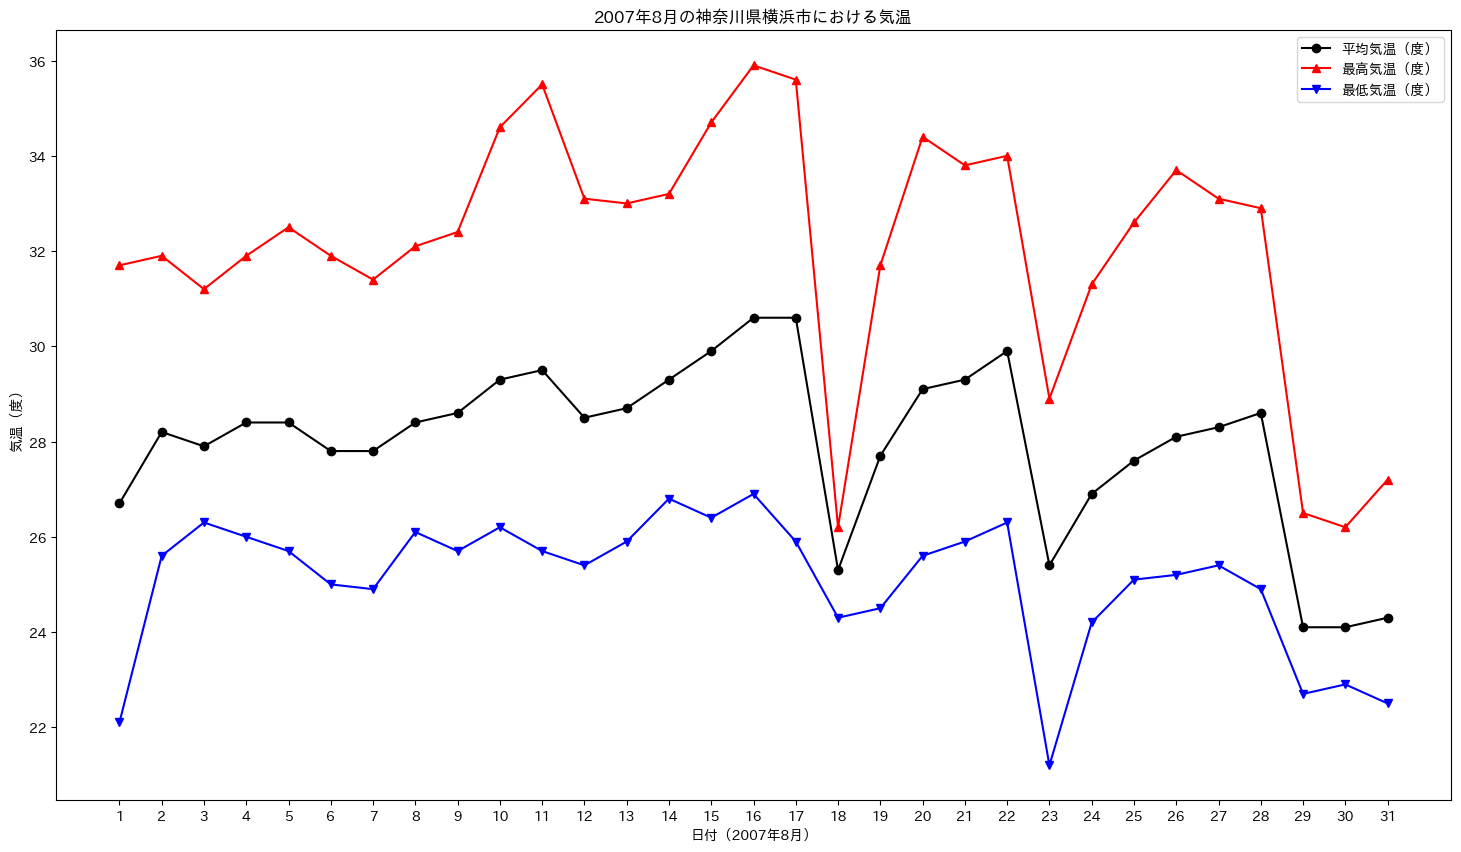

In [120]:
#(6)
#各種折れ線グラフを制作し、一つにまとめて表示する
#dfの後ろ2行は平均と標準偏差であるため省く
df_plot = df[:-2]

#x,y軸を定義する
x=df_plot["2007年8月（日）"]
y_mean=df_plot["平均気温（度）"]
y_max=df_plot["最高気温（度）"]
y_min=df_plot["最低気温（度）"]

#データをプロットし、折れ線グラフとして表示する
plt.figure(figsize=(18,10))
plt.xticks(x)
plt.xlabel("日付（2007年8月）")
plt.ylabel("気温（度）")
plt.title("2007年8月の神奈川県横浜市における気温")
plt.plot(x,y_mean,color="black",marker="o",label="平均気温（度）")
plt.plot(x,y_max,color="red",marker="^",label="最高気温（度）")
plt.plot(x,y_min,color="blue",marker="v",label="最低気温（度）")
plt.legend()
plt.show()

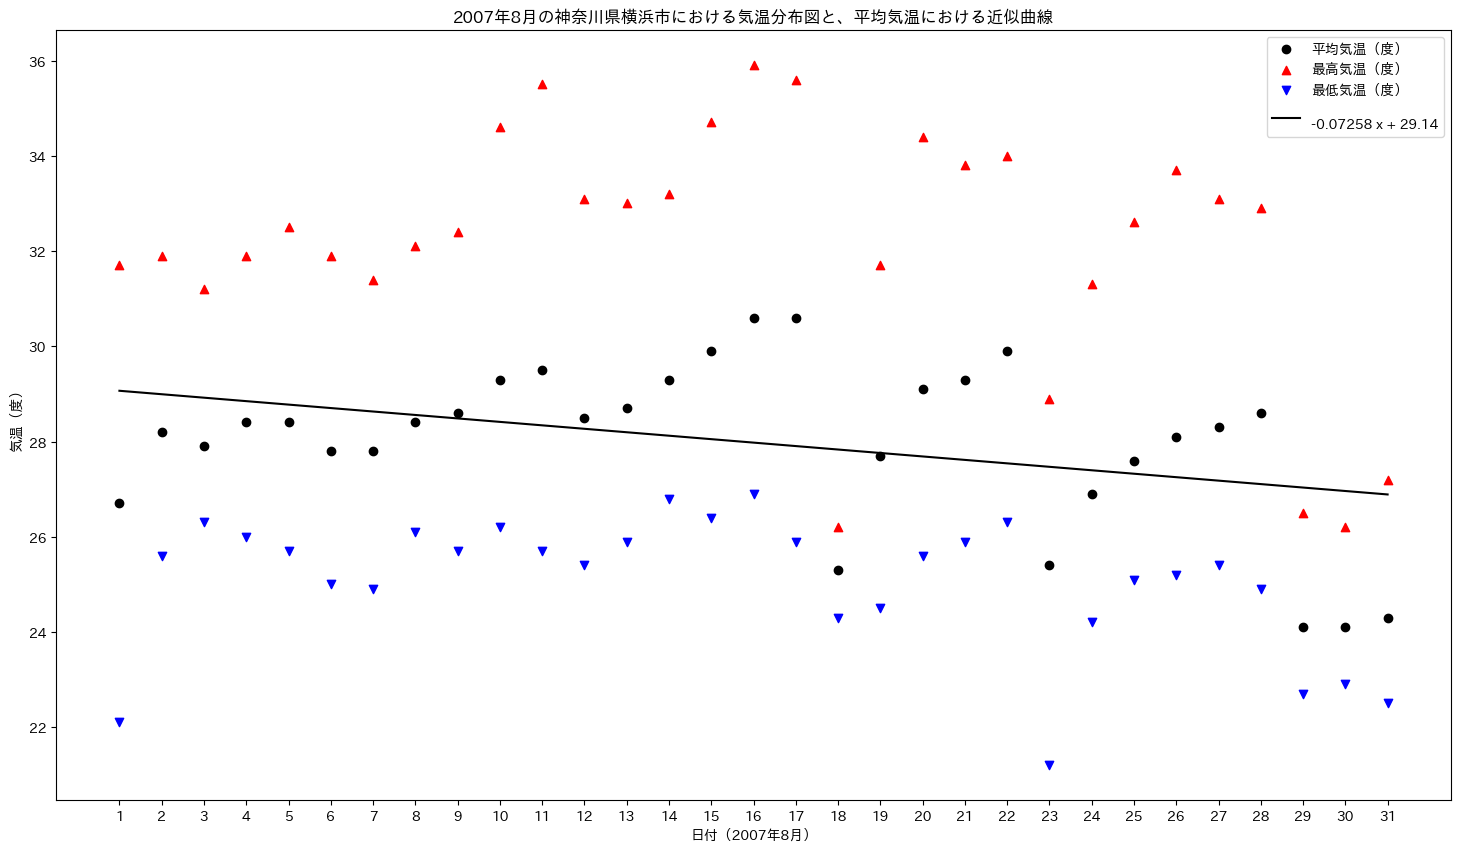

 
-0.07258 x + 29.14


In [119]:
#(7)
#numpyを用いて近似曲線を定義する
import numpy as np
coeffs_mean=np.polyfit(x,y_mean,1)
poly_func=np.poly1d(coeffs_mean)
x_fit_mean=np.linspace(x.min(), x.max(), 100)
y_fit_mean = poly_func(x_fit_mean)

#先ほどのグラフに近似曲線を追加する
plt.figure(figsize=(18,10))

plt.xticks(x)
plt.xlabel("日付（2007年8月）")
plt.ylabel("気温（度）")
plt.title("2007年8月の神奈川県横浜市における気温分布図と、平均気温における近似曲線")
plt.scatter(x,y_mean,color="black",marker="o",label="平均気温（度）")
plt.scatter(x,y_max,color="red",marker="^",label="最高気温（度）")
plt.scatter(x,y_min,color="blue",marker="v",label="最低気温（度）")
plt.plot(x_fit_mean,y_fit_mean,color="black",label=str(poly_func))
plt.legend()
plt.show()

#近似曲線の指揮を表示させる
print(poly_func)


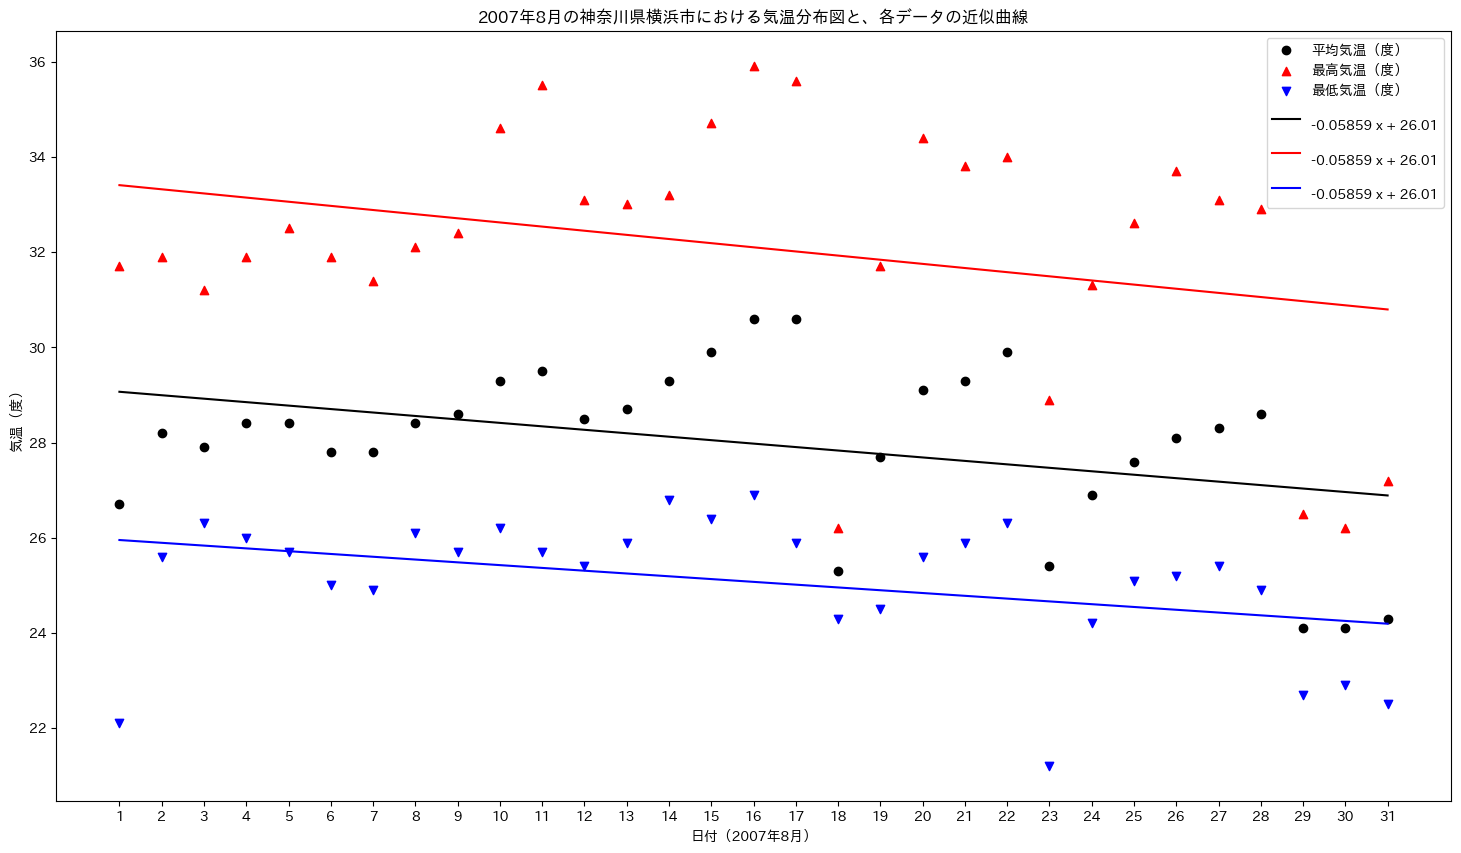

In [123]:
#（追加）最高気温、最低気温に関しても近似曲線を算出し、追加すると以下のようになる
import numpy as np
coeffs_mean=np.polyfit(x,y_mean,1)
poly_func=np.poly1d(coeffs_mean)
x_fit_mean=np.linspace(x.min(), x.max(), 100)
y_fit_mean = poly_func(x_fit_mean)

coeffs_max=np.polyfit(x,y_max,1)
poly_func=np.poly1d(coeffs_max)
x_fit_max=np.linspace(x.min(), x.max(), 100)
y_fit_max = poly_func(x_fit_max)

coeffs_min=np.polyfit(x,y_min,1)
poly_func=np.poly1d(coeffs_min)
x_fit_min=np.linspace(x.min(), x.max(), 100)
y_fit_min = poly_func(x_fit_min)



plt.figure(figsize=(18,10))
plt.xticks(x)
plt.xlabel("日付（2007年8月）")
plt.ylabel("気温（度）")
plt.title("2007年8月の神奈川県横浜市における気温分布図と、各データの近似曲線")
plt.scatter(x,y_mean,color="black",marker="o",label="平均気温（度）")
plt.scatter(x,y_max,color="red",marker="^",label="最高気温（度）")
plt.scatter(x,y_min,color="blue",marker="v",label="最低気温（度）")
plt.plot(x_fit_mean,y_fit_mean,color="black",label=str(poly_func))
plt.plot(x_fit_max,y_fit_max,color="red",label=str(poly_func))
plt.plot(x_fit_min,y_fit_min,color="blue",label=str(poly_func))
plt.legend()
plt.show()
